In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from statsmodels.graphics.tsaplots import plot_acf

In [2]:
from google.colab import files
uploaded = files.upload()

Saving VENTAS.xls to VENTAS.xls


In [3]:
df = pd.read_excel("VENTAS.xls",sheet_name=1)

In [4]:
df.head()

,ano_doc,per_doc,tip_doc,num_doc,cod_cli,nom_cli,valorfac,valordoc,valordes,subdoc,netdoc,codven,nomven,devolu,notas,codzona,nomzona,total
0,2026,5,10,F571143,900001,CLIENTE 001,307377,307377,126000,258300,384300,401,VENDEDOR 401,0,0,4,ANTIOQUIA,258300
1,2026,5,10,F571144,900002,CLIENTE 002,1319972,1319972,1063980,1109220,2173200,401,VENDEDOR 401,0,0,4,ANTIOQUIA,1109220
2,2026,5,10,F571145,900003,CLIENTE 003,359856,359856,270300,302400,572700,401,VENDEDOR 401,0,0,4,ANTIOQUIA,302400
3,2026,5,10,F571146,900004,CLIENTE 004,652525,652525,97060,548340,645400,401,VENDEDOR 401,0,0,4,ANTIOQUIA,548340
4,2026,5,10,F571149,900005,CLIENTE 005,2110870,2110870,1475760,1773840,3249600,401,VENDEDOR 401,0,0,4,ANTIOQUIA,1773840


In [5]:
x=df["subdoc"]
x.isna().sum()

np.int64(0)

**Histograma**

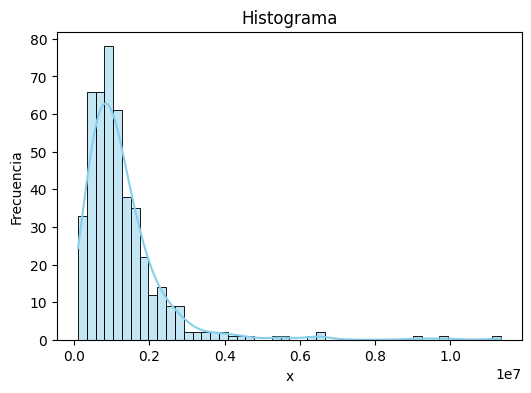

In [6]:
plt.figure(figsize=(6, 4))
sns.histplot(x, kde=True, color="skyblue")
plt.title("Histograma")
plt.xlabel("x")
plt.ylabel("Frecuencia")
plt.show()

**Scatterplot**

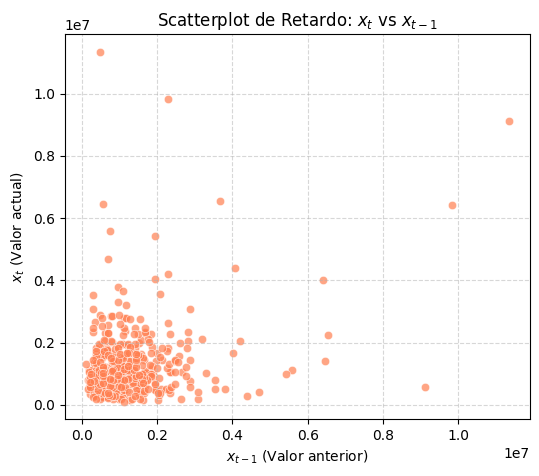

In [7]:
x_lag1 = x.shift(1)

plt.figure(figsize=(6, 5))
sns.scatterplot(x=x_lag1, y=x, color="coral", alpha=0.7)

plt.title("Scatterplot de Retardo: $x_t$ vs $x_{t-1}$")
plt.xlabel("$x_{t-1}$ (Valor anterior)")
plt.ylabel("$x_t$ (Valor actual)")
plt.grid(True, linestyle="--", alpha=0.5)

plt.show()

**Boxplot**

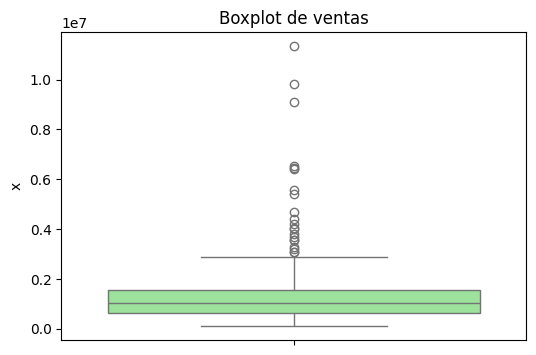

In [8]:
plt.figure(figsize=(6, 4))
sns.boxplot(y=x, color="lightgreen")
plt.title("Boxplot de ventas")
plt.ylabel("x")
plt.show()

**Autocorrelograma**

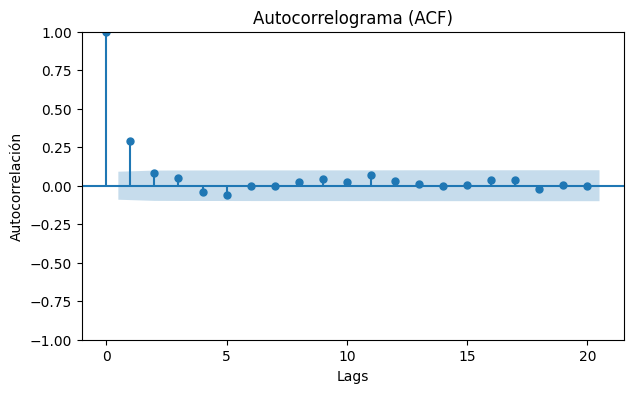

In [9]:
# Opción recomendada con bandas de confianza (statsmodels)
fig, ax = plt.subplots(figsize=(7, 4))
plot_acf(x, lags=20, ax=ax)
plt.title("Autocorrelograma (ACF)")
plt.xlabel("Lags")
plt.ylabel("Autocorrelación")
plt.show()

**Serie de tiempo**

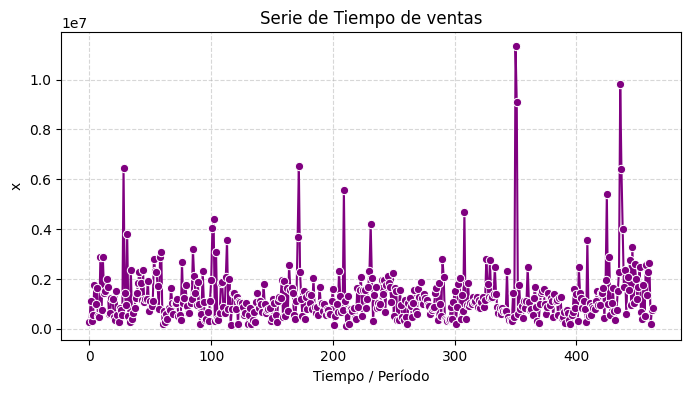

In [10]:
plt.figure(figsize=(8, 4))
sns.lineplot(x=range(len(x)), y=x, color="purple", marker="o")
plt.title("Serie de Tiempo de ventas")
plt.xlabel("Tiempo / Período")
plt.ylabel("x")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

**Calculo de Takt time**

1. calcular la demanda en unidades debido a que se encuentra en valor monetario actualmente

In [11]:
df["Demanda_unitaria"]=round(df["subdoc"]/12900,0)

**Calculo aproximado de la demanda diaria**

 El cálculo de la demanda diaria se realiza indexando los días hábiles reales mediante la siguiente fórmula:

$$\text{Demanda Diaria Promedio} = \frac{\sum \text{Demanda Histórica (May + Jun + Jul)}}{\sum \text{Días Hábiles Reales (May + Jun + Jul)}}$$

Donde los **Días Hábiles Reales** se calculan dinámicamente para cada mes restando del calendario:
* Los días de descanso dominical obligatorio (Artículo 171 del Código Sustantivo del Trabajo).
* Los días festivos oficiales de Colombia del año 2026.
* Los días de parada programada de planta (mantenimiento preventivo), en este caso 2 dias al mes según la información brindada por la empresa.

En este caso los días hábiles reales para los meses disponibles son:
* $\text{Dias_Disp_Mayo} = 31\ \text{Días_Calendario} \ - 5\ \text{Días_Descanso_Dominical}\ - 2\ \text{Días_Parada_Programada}\ - 2\ \text{Días_Festivos} = 22 \ \text{Días_Hábiles_Reales}$

* $\text{Dias_Disp_Junio} = 30\ \text{Días_Calendario} \ - 4\ \text{Días_Descanso_Dominical}\ - 2\ \text{Días_Parada_Programada}- 3\ \text{Días_Festivos} = 21 \ \text{Días_Hábiles_Reales}$

* $\text{Dias_Disp_Julio} = 31\ \text{Días_Calendario} \ - 4\ \text{Días_Descanso_Dominical}\ - 2\ \text{Días_Parada_Programada}- 2\ \text{Días_Festivos} = 23 \ \text{Días_Hábiles_Reales}$

In [12]:
Dias_Disp_Mayo=22
Dias_Disp_Junio=21
Dias_Disp_Julio=23
total_dias_hab= Dias_Disp_Mayo+Dias_Disp_Junio+Dias_Disp_Julio
print(f"El número de días habiles reales en los tres meses es: {total_dias_hab} Días")

El número de días habiles reales en los tres meses es: 66 Días


In [13]:
Dem_hist= df["Demanda_unitaria"].sum()
Dem_hist

np.float64(45798.0)

In [14]:
Dem_diaria_prom = round(Dem_hist/total_dias_hab,0)
print(f"La demanda diaria promedio es:{Dem_hist} unidades")

La demanda diaria promedio es:45798.0 unidades


2. calcular el tiempo disponible.

**Justificación del tiempo disponible:** Se considera una jornada laboral de
8 horas diarias, equivalentes a 480 minutos de operación. Según la información brindada por la empresa,
 los descansos del personal se gestionan mediante horarios
escalonados, de manera que los trabajadores toman sus pausas en diferentes
momentos y se garantiza la continuidad de las actividades productivas. Por lo
tanto, los períodos de descanso del personal no representan una interrupción de
la operación de la planta y no se descuentan del tiempo disponible para la
producción.

En consecuencia, el tiempo disponible considerado para el cálculo del **Takt
Time** es:

$
T_{\text{disponible}} = 8 \text{ horas} = 480 \text{ minutos por jornada}.
$

In [15]:
t_disponible=480

3.Calcular **Takt time** usando la formula $$Takt\  time\ =\frac{tiempo \ disponible}{demanda}$$

In [16]:
takt_time = t_disponible/Dem_diaria_prom
print(f"El takt time calculado es: {round(takt_time,2)} minutos/unidad")

El takt time calculado es: 0.69 minutos/unidad


**Cálculo de Throughput**

El throughput mide la cantidad de unidades producidas por unidad de tiempo, usando la fórmula:

$$Throughput = \frac{Unidades\ producidas}{Tiempo\ total}$$

Las unidades producidas corresponden a la demanda histórica total del periodo (May + Jun + Jul), ya calculada como `Dem_hist`. El tiempo total corresponde al tiempo disponible de planta acumulado en los días hábiles reales del mismo periodo, expresado en horas:

$$Tiempo\ total = \left(\frac{t_{disponible}}{60}\right) \times total\_dias\_hab$$

Con $t_{disponible}=480$ minutos/día (8 horas) y $total\_dias\_hab=66$ días, el tiempo total disponible en el periodo es de 528 horas.

In [17]:
t_disponible_horas = t_disponible/60
tiempo_total = t_disponible_horas*total_dias_hab
print(f"El tiempo total disponible en el periodo es: {tiempo_total} horas")

El tiempo total disponible en el periodo es: 528.0 horas


In [18]:
throughput = Dem_hist/tiempo_total
print(f"El throughput calculado es: {round(throughput,2)} unidades/hora")

El throughput calculado es: 86.74 unidades/hora


**Cálculo de WIP (Work In Process)**

El WIP se calcula mediante:

$$WIP = Throughput \times Tiempo\ de\ ciclo$$

El tiempo de ciclo compartido por la empresa para un tubo de tinte es de 3.5 a 5.5 horas. Con este rango, el WIP se calcula en su valor mínimo y máximo, usando el throughput de 86.74 unidades/hora obtenido en el paso anterior.

In [19]:
tiempo_ciclo_min = 3.5
tiempo_ciclo_max = 5.5

WIP_min = throughput*tiempo_ciclo_min
WIP_max = throughput*tiempo_ciclo_max

print(f"El WIP mínimo es: {round(WIP_min,2)} unidades")
print(f"El WIP máximo es: {round(WIP_max,2)} unidades")

El WIP mínimo es: 303.59 unidades
El WIP máximo es: 477.06 unidades


El nivel de inventario en proceso (WIP) para la línea de tubos de tinte se sitúa entre 303.59 y 477.06 unidades, en función del tiempo de ciclo real de cada unidad dentro del rango de 3.5 a 5.5 horas.